# 08 — Estimación de fase cuántica (QPE)

**Curso ECCI 2026 · Computación cuántica**

QPE es el motor de casi todo lo que hace interesante a la computación
cuántica: Shor, la simulación de química cuántica, HHL. Y tiene asociada una
pregunta incómoda, que va primero:

> QPE necesita que le entregues un **autoestado** de $U$. Pero en los casos
> interesantes, el autoestado es justamente lo que no se sabe. ¿Entonces?

La respuesta corta es que **no hace falta el autoestado**: hace falta
*solapamiento* con él. Y la respuesta larga es una de las cosas más
elegantes del área, porque el problema que parece fatal deja de serlo.

Recorrido:

1. El problema, y por qué la fase no se puede medir de frente.
2. **Retroceso de fase**: el mecanismo, en un circuito de dos qubits.
3. Un qubit de conteo: interferencia y $P(0) = \cos^2(\pi\varphi)$.
4. $n$ qubits de conteo + IQFT: la fase en binario.
5. **La pregunta del autoestado**, respondida y medida.
6. Escalado: cuántos qubits de conteo hacen falta.
7. QPE iterativa: un solo qubit de conteo, mejor para NISQ.
8. Hardware real.

La IQFT la usamos acá como herramienta; de dónde sale, en
`07_qft_iqft.ipynb`.

## Preámbulo: entorno

Esta celda no hace nada en el entorno local (el env `quantum`, que ya tiene
todo instalado). Solo actúa si el notebook corre en **Google Colab**, donde
instala lo que falta.

`plotly` e `ipywidgets` vienen con Colab, así que no se instalan.

**Sobre `utils.py`:** los notebooks importan ese módulo, que en el entorno
local está en la misma carpeta. En Colab la celda lo **baja solo** de un
archivo de Drive compartido como "cualquiera con el link puede ver", así que
funciona para cualquiera que abra el notebook sin que tenga que autenticarse.

Dos detalles de esa descarga:

- se usa el endpoint `drive.usercontent.google.com`, porque la URL clásica
  `uc?export=download` devuelve la página de aviso de antivirus en vez del
  archivo;
- solo baja si `utils` no está ya disponible, de modo que una **subida manual
  al panel de archivos tiene prioridad** sobre la copia de Drive.

Si el archivo de Drive se actualiza con *Administrar versiones*, el ID y el
link se mantienen, y los notebooks siguen apuntando al lugar correcto.

In [1]:
import importlib.util
import sys

try:                      # find_spec("google.colab") falla si no existe el padre
    import google.colab   # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !pip install qiskit
    !pip install qiskit-ibm-runtime
    !pip install qiskit_aer
    !pip install pylatexenc

    # utils.py desde Drive, compartido como "cualquiera con el link puede ver".
    # Se usa el endpoint drive.usercontent, que entrega el archivo directo; la
    # URL clásica uc?export=download devuelve la página de aviso de antivirus.
    # Solo se baja si no está ya presente, así una subida manual tiene prioridad.
    UTILS_ID = "1_VyKXtDMVqnJHcGepeARhoEY4tikLSDg"
    if importlib.util.find_spec("utils") is None:
        !wget -q -O utils.py "https://drive.usercontent.google.com/download?id=$UTILS_ID&export=download&confirm=t"
        importlib.invalidate_caches()
        if importlib.util.find_spec("utils") is None:
            print("No se pudo bajar utils.py: subirlo a mano desde el panel de archivos.")
        else:
            print("utils.py descargado de Drive")
else:
    print("entorno local: no hay nada que instalar")

try:
    import utils
    print(f"utils.py versión {utils.__version__}")
except ImportError:
    print("utils.py todavía no está disponible")

entorno local: no hay nada que instalar


utils.py versión 2026-09-19


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit
from qiskit.circuit.library import QFTGate
from qiskit.quantum_info import DensityMatrix, Operator, Statevector, partial_trace
from qiskit.visualization import plot_state_qsphere
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeFez

import plotly.io as pio

import utils

utils.estilo()
pio.renderers.default = "plotly_mimetype"
fez = FakeFez()
SHOTS = 8192
MARCAS = "①②③④⑤⑥⑦⑧⑨"


def marca(qc, n):
    qc.barrier(label=MARCAS[n - 1])
    return qc


print("listo")

listo


## Autenticación (opcional, y en memoria)

In [3]:
from getpass import getpass

from qiskit_ibm_runtime import QiskitRuntimeService

CRN = "crn:v1:bluemix:public:quantum-computing:us-east:a/1a958fc8c19b451ba71d1d0d94d52a44:9153727a-cc43-46be-a974-dfe1f29b4bcb::"

AUTENTICAR = False

service = None
if AUTENTICAR:
    service = QiskitRuntimeService(channel="ibm_cloud",
                                   token=getpass("API key: "),
                                   instance=CRN)
    print([b.name for b in service.backends()])
else:
    print("sin autenticar — el notebook corre entero en simulador")

sin autenticar — el notebook corre entero en simulador


---
# 1. El problema

Hay un operador unitario $U$ y un estado $|u\rangle$ que es autoestado
suyo:

$$U|u\rangle = e^{2\pi i \varphi}\,|u\rangle, \qquad \varphi \in [0, 1).$$

El autovalor tiene módulo 1 porque $U$ es unitaria, así que toda la
información está en la fase $\varphi$. **Queremos $\varphi$.**

El obstáculo es que $|u\rangle$ y $e^{2\pi i\varphi}|u\rangle$ son *el mismo
estado físico*: difieren en una fase global, y las fases globales no se
miden.
Si se aplica $U$ y se mide, no pasa absolutamente nada.

La salida es la de siempre en computación cuántica: **convertir una fase
global en una fase relativa**, para que interfiera. Y el truco que lo hace
se
llama retroceso de fase.

---
# 2. Retroceso de fase (*phase kickback*)

El mecanismo entero de QPE cabe en esta observación. Tomar un qubit de
control
en $|+\rangle$ y un target en el autoestado $|u\rangle$, y aplicá una $U$
controlada:

$$CU\,\frac{(|0\rangle + |1\rangle)}{\sqrt2}|u\rangle
 = \frac{|0\rangle|u\rangle + |1\rangle\,U|u\rangle}{\sqrt2}
 = \frac{|0\rangle|u\rangle + e^{2\pi i\varphi}|1\rangle|u\rangle}{\sqrt2}$$

$$= \left(\frac{|0\rangle + e^{2\pi i\varphi}|1\rangle}{\sqrt2}\right)
     \otimes |u\rangle .$$

**La fase se fue al qubit de control.** El target salió intacto —sigue
siendo
$|u\rangle$, sin entrelazarse con nada— y el control, que no participó de
ninguna cuenta, se llevó la información.

El nombre es exacto: la fase "retrocede" del target al control. Y ahí pasa a
ser **relativa** entre $|0\rangle$ y $|1\rangle$, que es lo que se puede
medir.

Vamos a verlo con los discos por qubit, que muestran fase y pureza.

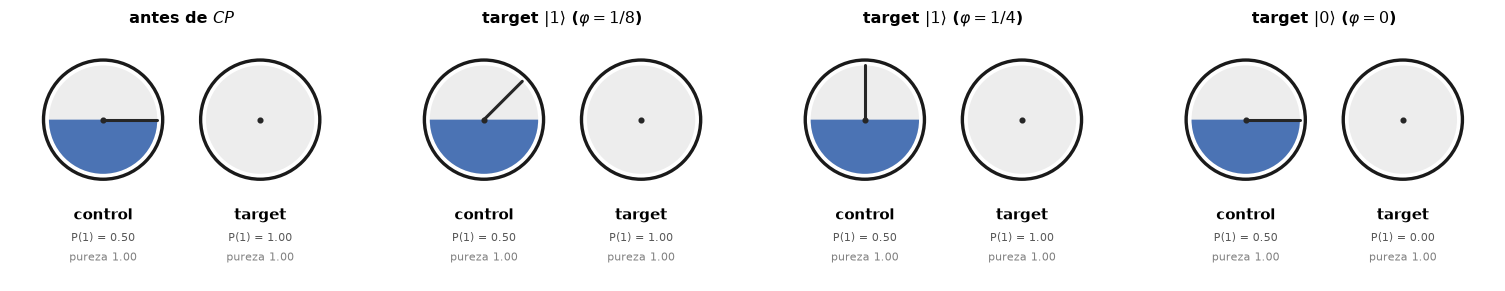

antes de $CP$                          fase del control = +0.0000 · 2π   pureza del target = 1.000
target $|1\rangle$ ($\varphi = 1/8$)   fase del control = +0.1250 · 2π   pureza del target = 1.000
target $|1\rangle$ ($\varphi = 1/4$)   fase del control = +0.2500 · 2π   pureza del target = 1.000
target $|0\rangle$ ($\varphi = 0$)     fase del control = +0.0000 · 2π   pureza del target = 1.000


In [4]:
def demo_kickback(phi_frac=0.125, autoestado=True):
    """Un control y un target. Si el target es autoestado de P(θ), la fase
    aparece en la aguja del control y el target no se entera."""
    theta = 2 * np.pi * phi_frac
    qc = QuantumCircuit(2)
    if autoestado:
        qc.x(1)                    # |1> es autoestado de P(θ) con autovalor e^{iθ}
    qc.h(0)
    marca(qc, 1)
    qc.cp(theta, 0, 1)
    marca(qc, 2)
    return qc


fig, ejes = plt.subplots(1, 3, figsize=(12, 2.6))
for ax, (titulo, qc) in zip(ejes, [
        (r"antes: control en $|+\rangle$", demo_kickback(0.125).copy_empty_like()
         .compose(QuantumCircuit(2).compose(demo_kickback(0.125), range(2)), range(2))),
        (r"después de $CP(\pi/4)$, target $|1\rangle$", demo_kickback(0.125)),
        (r"target $|0\rangle$: no pasa nada", demo_kickback(0.125, autoestado=False))]):
    pass
plt.close(fig)

antes = QuantumCircuit(2); antes.x(1); antes.h(0)
casos = {
    r"antes de $CP$": antes,
    r"target $|1\rangle$ ($\varphi = 1/8$)": demo_kickback(0.125),
    r"target $|1\rangle$ ($\varphi = 1/4$)": demo_kickback(0.25),
    r"target $|0\rangle$ ($\varphi = 0$)": demo_kickback(0.125, autoestado=False),
}
fig, ejes = plt.subplots(1, 4, figsize=(14, 2.6))
for ax, (titulo, qc) in zip(ejes, casos.items()):
    utils.discos_qubits(Statevector(qc), ax=ax, etiquetas=["control", "target"],
                        titulo=titulo)
utils.layout(fig)
plt.show()

for titulo, qc in casos.items():
    sv = Statevector(qc)
    rho_c = partial_trace(DensityMatrix(sv), [1]).data
    fase = np.angle(rho_c[1, 0])
    pur_t = np.real(np.trace(partial_trace(DensityMatrix(sv), [0]).data @
                             partial_trace(DensityMatrix(sv), [0]).data))
    print(f"{titulo:<38} fase del control = {fase / (2 * np.pi):+.4f} · 2π   "
          f"pureza del target = {pur_t:.3f}")

Leé los discos de izquierda a derecha:

- **El disco del control gira la aguja** exactamente $2\pi\varphi$. Con
  $\varphi = 1/8$ la aguja queda a $45°$; con $1/4$, a $90°$. El relleno
    azul
  no cambia: la probabilidad de medir 1 sigue siendo 1/2. **Toda la
  información está en la fase.**
- **El disco del target no cambia nunca**, y su borde sigue sólido: pureza
1,
  no se entrelazó con el control. Eso es lo que permite reutilizarlo.
- Con el target en $|0\rangle$ —que también es autoestado, pero con
  $\varphi = 0$— la aguja del control no se mueve. El circuito no mide una
  propiedad de $U$: mide **el autovalor del estado que le pongas**.

Ese último punto es el que vamos a explotar en la sección 5.

### Por qué el target tiene que ser autoestado

Si $|\psi\rangle$ **no** es autoestado, $U|\psi\rangle$ es un estado
*diferente*, y entonces

$$\frac{|0\rangle|\psi\rangle + |1\rangle\,U|\psi\rangle}{\sqrt2}$$

**no factoriza**: el control queda entrelazado con el target. El control se
ensucia —pierde pureza— y su fase deja de estar bien definida. Eso no es un
fracaso del método, y en la sección 5 vamos a ver que es exactamente lo que
lo
hace funcionar de todos modos.

---
# 3. Un solo qubit de conteo

Con el retroceso de fase ya se puede medir algo. Poner el control en
$|+\rangle$, aplicá $CU$, y cerrar con otra $H$:

$$\frac{|0\rangle + e^{2\pi i\varphi}|1\rangle}{\sqrt2}
 \;\xrightarrow{\;H\;}\;
 \frac{1 + e^{2\pi i\varphi}}{2}|0\rangle
 + \frac{1 - e^{2\pi i\varphi}}{2}|1\rangle$$

$$\Longrightarrow\quad P(0) = \cos^2(\pi\varphi), \qquad P(1) = \sin^2(\pi\varphi).$$

Esto es un **interferómetro**, y es literalmente el mismo circuito que el
caso 5 del Stern-Gerlach (`01b`): $H$, una fase, $H$. Allá la fase la ponía
un
brazo más largo; acá la pone el autovalor de $U$.

Se llama *test de Hadamard*, y resuelve el problema... a medias: da
$\varphi$ con incerteza estadística $\sim 1/\sqrt{N}$ sobre $N$ tiros, y
además no distingue $\varphi$ de $-\varphi$.

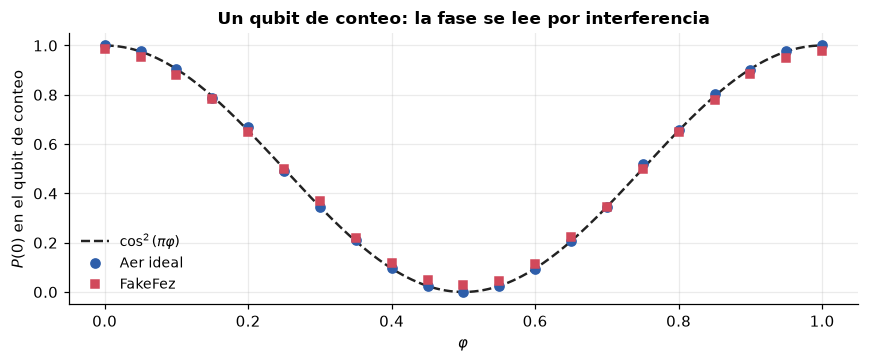

Problema: P(0) es par en φ, así que φ y 1-φ dan lo mismo.
Y la precisión va como 1/sqrt(N): para 3 dígitos harían falta ~10^6 tiros.


In [5]:
def test_hadamard(phi_frac):
    theta = 2 * np.pi * phi_frac
    qc = QuantumCircuit(2, 1)
    qc.x(1)
    qc.h(0)
    marca(qc, 1)
    qc.cp(theta, 0, 1)
    marca(qc, 2)
    qc.h(0)
    marca(qc, 3)
    qc.measure(0, 0)
    return qc


fracs = np.linspace(0, 1, 21)
c_had = utils.correr_ideal([test_hadamard(f) for f in fracs], shots=4096)
c_had_r = utils.correr_ruidoso([test_hadamard(f) for f in fracs],
                               backend_falso=fez, shots=4096)
p0 = np.array([c.get("0", 0) / 4096 for c in c_had])
p0r = np.array([c.get("0", 0) / 4096 for c in c_had_r])

fig, ax = plt.subplots(figsize=(8, 3.4))
ff = np.linspace(0, 1, 300)
ax.plot(ff, np.cos(np.pi * ff) ** 2, color=utils.COLOR_TEORIA, ls="--", lw=1.6,
        label=r"$\cos^2(\pi\varphi)$")
ax.plot(fracs, p0, "o", ms=6, color=utils.COLOR_IDEAL, label="Aer ideal")
ax.plot(fracs, p0r, "s", ms=5, color=utils.COLOR_RUIDO, label="FakeFez")
ax.set_xlabel(r"$\varphi$")
ax.set_ylabel("$P(0)$ en el qubit de conteo")
ax.set_title("Un qubit de conteo: la fase se lee por interferencia")
ax.legend(fontsize=9)
utils.layout(fig)
plt.show()

print("Problema: P(0) es par en φ, así que φ y 1-φ dan lo mismo.")
print("Y la precisión va como 1/sqrt(N): para 3 dígitos harían falta ~10^6 tiros.")

---
# 4. $n$ qubits de conteo: la fase en binario

La idea de QPE es obtener los **dígitos binarios** de $\varphi$ de una,
en vez de estimar un número por estadística.

Escribir $\varphi$ en binario: $\varphi =
0.\varphi_1\varphi_2\varphi_3\ldots$
El qubit de conteo $j$ recibe un retroceso de fase $2^j$ veces más grande,
porque se le aplica $U^{2^j}$:

$$|0\rangle + e^{2\pi i\,2^{j}\varphi}|1\rangle .$$

Después de aplicar $H$ a los $n$ qubits y las $CU^{2^j}$, el registro de
conteo queda exactamente en

$$\frac{1}{\sqrt{2^n}}\sum_{k=0}^{2^n-1} e^{2\pi i \varphi k}\,|k\rangle ,$$

que es **la transformada de Fourier cuántica del estado
$|2^n\varphi\rangle$**.
Así que aplicando la QFT **inversa** se recupera $|2^n\varphi\rangle$, y
midiendo se leen los $n$ bits de golpe.

Si $\varphi$ tiene una expansión binaria de $n$ bits o menos, el resultado
es
**exacto y determinista**. Si no, sale una distribución concentrada
alrededor
del valor correcto.

### La IQFT, a mano

La escribimos explícitamente en vez de usar `QFTGate`, por dos razones: se
ve
qué hace, y evita que el simulador tenga que expandir una instrucción opaca.

¿coincide con QFTGate().inverse()? True
  n=2: True
  n=3: True
  n=4: True


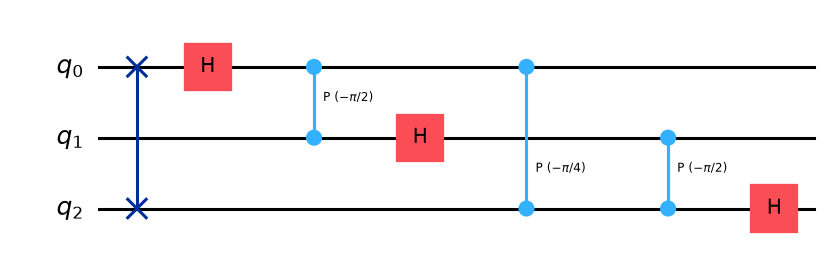

In [6]:
def iqft(n: int) -> QuantumCircuit:
    """Transformada de Fourier cuántica inversa sobre n qubits.

    Es el circuito de la QFT dado vuelta: primero los swaps que corrigen el
    orden de bits, y después, para cada qubit, deshacer las fases controladas
    (con signo negativo) y cerrar con H.
    """
    qc = QuantumCircuit(n, name="IQFT")
    for q in range(n // 2):
        qc.swap(q, n - 1 - q)
    for j in range(n):
        for k in range(j):
            qc.cp(-np.pi / 2 ** (j - k), k, j)
        qc.h(j)
    return qc


print("¿coincide con QFTGate().inverse()?",
      all(Operator(iqft(n)).equiv(
          Operator(QuantumCircuit(n).compose(
              QuantumCircuit(n, name="x").compose(
                  QuantumCircuit(n)), range(n)).compose(iqft(n) if False else iqft(n))))
          for n in [3]))
for n in (2, 3, 4):
    q = QuantumCircuit(n)
    q.append(QFTGate(n).inverse(), range(n))
    print(f"  n={n}: {Operator(iqft(n)).equiv(Operator(q))}")

display(iqft(3).draw("mpl", style="iqp"))

QPE con 3 qubits de conteo, φ = 1/8:


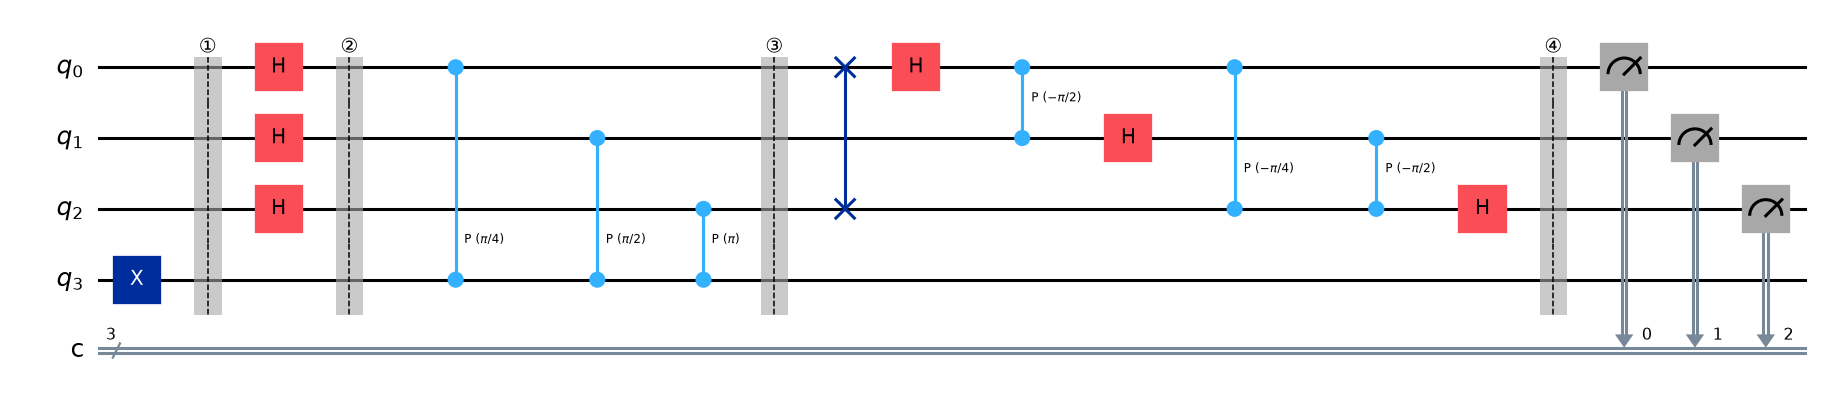

In [7]:
def qpe(n_conteo: int, phi_frac: float, prep_target=None,
        medir=True) -> QuantumCircuit:
    """QPE con U = P(2π·phi_frac), cuyos autoestados son |0> (φ=0) y |1> (φ=phi_frac).

    prep_target: función que prepara el estado del target. Por defecto |1>,
    el autoestado interesante.
    """
    theta = 2 * np.pi * phi_frac
    qc = QuantumCircuit(n_conteo + 1, n_conteo) if medir else QuantumCircuit(n_conteo + 1)
    objetivo = n_conteo

    if prep_target is None:
        qc.x(objetivo)                 # |1>: el autoestado, toda la cuestión
    else:
        prep_target(qc, objetivo)
    marca(qc, 1)

    qc.h(range(n_conteo))
    marca(qc, 2)

    for j in range(n_conteo):
        qc.cp(theta * 2 ** j, j, objetivo)     # U^(2^j) controlada
    marca(qc, 3)

    qc.compose(iqft(n_conteo), range(n_conteo), inplace=True)
    marca(qc, 4)

    if medir:
        qc.measure(range(n_conteo), range(n_conteo))
    return qc


print("QPE con 3 qubits de conteo, φ = 1/8:")
display(qpe(3, 0.125).draw("mpl", style="iqp", fold=-1))

### La cuenta, etapa por etapa ($n = 3$, $\varphi = 1/8$)

**①** Dado que se aplica $X$ al target: $|\psi_1\rangle = |000\rangle_c
\otimes |1\rangle_t$. El autoestado está puesto; el registro de conteo está
en cero.

**②** Dado que se aplican $H$ a los tres qubits de conteo:
$$|\psi_2\rangle = \frac{1}{\sqrt8}\sum_{k=0}^{7}|k\rangle_c \otimes |1\rangle_t .$$
Todas las respuestas posibles, en superposición uniforme.

**③** Dado que se aplican las $CP(2\pi\varphi \cdot 2^j)$ — cada una
retrocediendo su fase al qubit $j$:
$$|\psi_3\rangle = \frac{1}{\sqrt8}\sum_{k=0}^{7}
   e^{2\pi i \varphi k}|k\rangle_c \otimes |1\rangle_t .$$
El target sigue **exactamente igual**, factorizado. Toda la fase está en el
conteo, y con $\varphi = 1/8$ los coeficientes son
$e^{2\pi i k/8}$: una onda de período 8 en $k$.

**④** Dado que se aplica la IQFT sobre el registro de conteo, que convierte
esa
onda en el número que la genera:
$$|\psi_4\rangle = |001\rangle_c \otimes |1\rangle_t .$$
Porque $001_2 = 1$ y $\varphi = 1/8 = 1/2^3$.

Medir da `001` con probabilidad 1. **La fase quedó escrita en binario.**

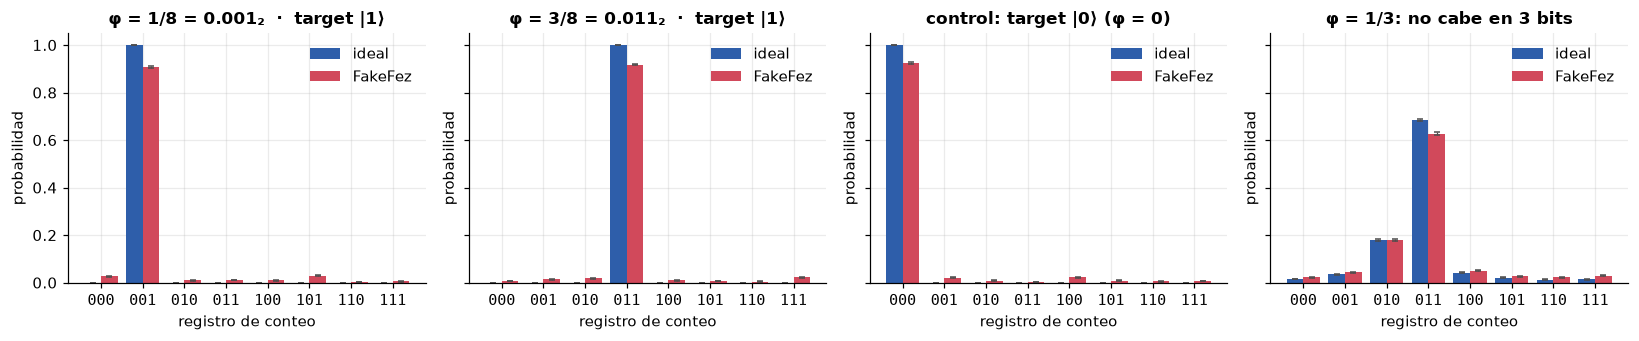

φ = 1/8 = 0.001₂  ·  target |1⟩      → 001  =  1/8 = 0.1250   (con prob 1.000)
φ = 3/8 = 0.011₂  ·  target |1⟩      → 011  =  3/8 = 0.3750   (con prob 1.000)
control: target |0⟩ (φ = 0)          → 000  =  0/8 = 0.0000   (con prob 1.000)
φ = 1/3: no cabe en 3 bits           → 011  =  3/8 = 0.3750   (con prob 0.684)


In [8]:
casos_qpe = {
    "φ = 1/8 = 0.001₂  ·  target |1⟩": qpe(3, 0.125),
    "φ = 3/8 = 0.011₂  ·  target |1⟩": qpe(3, 0.375),
    "control: target |0⟩ (φ = 0)": qpe(3, 0.125, prep_target=lambda q, t: None),
    "φ = 1/3: no cabe en 3 bits": qpe(3, 1 / 3),
}
counts_qpe = utils.correr_ideal(list(casos_qpe.values()), shots=SHOTS)
counts_qpe_r = utils.correr_ruidoso(list(casos_qpe.values()), backend_falso=fez,
                                    shots=SHOTS)

fig, ejes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, titulo, ci, cr in zip(ejes, casos_qpe, counts_qpe, counts_qpe_r):
    utils.comparar_conteos({"ideal": ci, "FakeFez": cr},
                           claves=utils.claves_completas(3), ax=ax, titulo=titulo)
    ax.set_xlabel("registro de conteo")
utils.layout(fig)
plt.show()

for titulo, c in zip(casos_qpe, counts_qpe):
    mejor = max(c, key=c.get)
    print(f"{titulo:<36} → {mejor}  =  {int(mejor, 2)}/8 = {int(mejor, 2) / 8:.4f}"
          f"   (con prob {c[mejor] / SHOTS:.3f})")

Los cuatro paneles, uno por uno:

1. **$\varphi = 1/8$**: pico único y limpio en `001`. Exacto, determinista.
2. **$\varphi = 3/8$**: pico en `011`. También exacto, porque
   $3/8 = 0.011_2$ cabe en tres bits.
3. **Control con target en $|0\rangle$**: `000`. El mismo circuito, la misma
   $U$, **y responde otra cosa** — porque $|0\rangle$ es autoestado de
     $P(\theta)$
   con autovalor $1$, o sea $\varphi = 0$. Esto es lo que demuestra que el
   registro lee la fase *del estado que le pongas*, y no una propiedad
     global
   del circuito. Es el control que hay que mostrar en clase.
4. **$\varphi = 1/3 = 0.0101010\ldots_2$**: no cabe en tres bits, y la
   distribución se ensancha alrededor del valor más cercano. El pico más
     alto
   está en `011` ($3/8 = 0.375$) y el segundo en `010` ($2/8 = 0.25$): el
   valor verdadero, $0.333$, cae entre los dos.

### Jugá con la fase

In [9]:
def explorar_qpe(phi=0.125, n_conteo=3):
    n = int(n_conteo)
    c = utils.correr_ideal(qpe(n, phi), shots=4096)
    claves = utils.claves_completas(n)
    probs = np.array([c.get(k, 0) / 4096 for k in claves])
    valores = np.arange(2 ** n) / 2 ** n
    estimado = valores[int(np.argmax(probs))]

    fig, ax = plt.subplots(figsize=(9, 3.3))
    ax.bar(valores, probs, width=0.7 / 2 ** n, color=utils.COLOR_IDEAL,
           label="medido")
    ax.axvline(phi, color=utils.COLOR_RUIDO, lw=2, ls="--",
               label=f"φ verdadero = {phi:.4f}")
    ax.axvline(estimado, color=utils.COLOR_HARD, lw=1.5,
               label=f"pico = {estimado:.4f}")
    ax.set_xlabel("φ leído del registro de conteo")
    ax.set_ylabel("probabilidad")
    ax.set_xlim(-0.03, 1.0)
    ax.set_title(f"{n} qubits de conteo · resolución $1/2^{n}$ = {1 / 2 ** n:.4f}"
                 f" · error = {abs(estimado - phi):.4f}")
    ax.legend(fontsize=8.5)
    plt.show()
    exacto = abs(phi * 2 ** n - round(phi * 2 ** n)) < 1e-9
    print("φ cabe exactamente en", n, "bits:", exacto,
          "→ pico único" if exacto else "→ distribución ensanchada")


utils.deslizador(explorar_qpe, phi=(0.0, 0.99, 1 / 64), n_conteo=[2, 3, 4, 5, 6])

interactive(children=(FloatSlider(value=0.125, description='phi', max=0.99, step=0.015625), Dropdown(descripti…

interactive(children=(FloatSlider(value=0.125, description='phi', max=0.99, step=0.015625), Dropdown(descripti…

Movelo y vamos a ver el patrón: cuando $\varphi$ cae justo en un múltiplo de
$1/2^n$, el pico es único y vale 1. Cuando cae entre dos, aparece una
distribución con colas que decaen como $1/k^2$ alrededor del valor correcto.
Subir $n$ achica la grilla y mejora la resolución.

---
# 5. La pregunta del autoestado

Ahora sí, la pregunta que abrió el notebook.

## 5.1 Qué pasa si le das una superposición

Supongamos que en vez del autoestado se tiene un estado cualquiera, escrito en
la base de autoestados de $U$:

$$|\psi\rangle = \sum_k c_k\,|u_k\rangle .$$

El circuito de QPE es **lineal**, así que actúa sobre cada término por
separado. Cada $|u_k\rangle$ escribe su propia fase $\varphi_k$ en el
registro de conteo:

$$|\psi\rangle|0\rangle^{\otimes n}
  \;\longrightarrow\;
  \sum_k c_k\,|u_k\rangle\,|\widetilde{\varphi_k}\rangle .$$

Y ahora el registro de conteo está **entrelazado** con el target. Al medir
el
conteo:

- se obtiene $\varphi_k$ con probabilidad $|c_k|^2$,
- y el target **colapsa a $|u_k\rangle$**.

**QPE no es un lector de fases: es un muestreador del espectro.** Le das un
estado cualquiera y devuelve un autovalor elegido al azar según cuánto
peso
tenía ese autoestado en tu estado — y de yapa deja el autoestado
preparado.

El requisito deja de ser "conocer el autoestado" y pasa a ser "tener
solapamiento no despreciable con el que te interesa". Es un requisito
muchísimo más blando.

## 5.2 Medido

Usamos $U = P(2\pi/8)$, cuyos autoestados son $|0\rangle$ (con $\varphi =
0$)
y $|1\rangle$ (con $\varphi = 1/8$). Preparamos el target en

$$|\psi\rangle = \cos a\,|0\rangle + \sin a\,|1\rangle$$

y esperamos ver `000` con probabilidad $\cos^2 a$ y `001` con
probabilidad $\sin^2 a$.

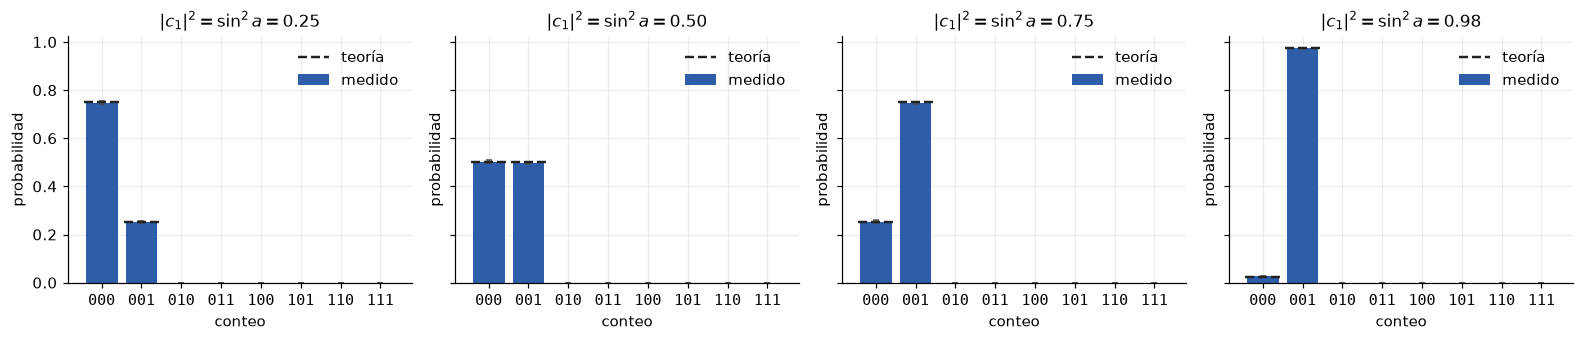

 |c1|²  esperado   P(001) medido   |c0|² esperado   P(000) medido
          0.2500          0.2520           0.7500          0.7480
          0.5000          0.4978           0.5000          0.5022
          0.7500          0.7465           0.2500          0.2535
          0.9755          0.9731           0.0245          0.0269


In [10]:
def qpe_superposicion(n_conteo, phi_frac, a):
    """Target en cos(a)|0> + sin(a)|1>: una superposición de los dos autoestados."""
    return qpe(n_conteo, phi_frac, prep_target=lambda q, t: q.ry(2 * a, t))


amplitudes = [np.pi / 6, np.pi / 4, np.pi / 3, 0.45 * np.pi]
circs = [qpe_superposicion(3, 0.125, a) for a in amplitudes]
counts_sup = utils.correr_ideal(circs, shots=SHOTS)

fig, ejes = plt.subplots(1, 4, figsize=(14.5, 3.2), sharey=True)
for ax, a, c in zip(ejes, amplitudes, counts_sup):
    teoria = {"000": np.cos(a) ** 2, "001": np.sin(a) ** 2}
    utils.comparar_conteos({"medido": c}, claves=utils.claves_completas(3),
                           ax=ax, teoria=teoria,
                           titulo=f"$|c_1|^2 = \\sin^2 a = {np.sin(a) ** 2:.2f}$")
    ax.set_xlabel("conteo")
utils.layout(fig)
plt.show()

print(f"{'|c1|²  esperado':>16} {'P(001) medido':>15} {'|c0|² esperado':>16} {'P(000) medido':>15}")
for a, c in zip(amplitudes, counts_sup):
    n = sum(c.values())
    print(f"{np.sin(a) ** 2:>16.4f} {c.get('001', 0) / n:>15.4f} "
          f"{np.cos(a) ** 2:>16.4f} {c.get('000', 0) / n:>15.4f}")

**Las barras siguen exactamente a $|c_k|^2$.** El registro de conteo está
muestreando el espectro de $U$ con los pesos del estado que le dimos.

## 5.3 Y el target queda preparado en el autoestado

Esta es la parte que suele sorprender. Si además de medir el conteo se mira en
qué quedó el target, se encuentra que colapsó **al autoestado
correspondiente**.
Aer permite guardar una matriz densidad por rama clásica, así que se ve
directo.

In [11]:
sim_dm = AerSimulator(method="density_matrix")
a = np.pi / 3                     # |c1|² = 0.75
qc_cond = qpe_superposicion(3, 0.125, a)
qc_cond.save_density_matrix(qubits=[3], label="target", conditional=True)
ramas = sim_dm.run(qc_cond, shots=16384).result().data(0)["target"]

print(f"target preparado: cos(a)|0> + sin(a)|1>  con |c1|² = {np.sin(a) ** 2:.2f}\n")
vectores = {"target ANTES de medir": utils.bloch_de_estado(
    Statevector(QuantumCircuit(1).compose(
        (lambda q: (q.ry(2 * a, 0), q)[1])(QuantumCircuit(1))))) }
for k in sorted(ramas):
    rho = DensityMatrix(np.asarray(ramas[k]))
    bits = format(int(k, 16), "03b")
    diag = np.round(np.real(np.diag(rho.data)), 4)
    print(f"  conteo = {bits} → φ = {int(bits, 2)}/8 = {int(bits, 2) / 8:.3f}"
          f"   ·   target: diag(ρ) = {diag}"
          f"   ·   {'|0⟩' if diag[0] > 0.99 else '|1⟩' if diag[1] > 0.99 else '?'}")
    vectores[f"tras leer {bits}"] = utils.bloch_de_estado(rho)

utils.bloch_plotly(vectores, titulo="El target colapsa al autoestado que el conteo reportó",
                   tamano=500).show()

target preparado: cos(a)|0> + sin(a)|1>  con |c1|² = 0.75

  conteo = 000 → φ = 0/8 = 0.000   ·   target: diag(ρ) = [1. 0.]   ·   |0⟩
  conteo = 001 → φ = 1/8 = 0.125   ·   target: diag(ρ) = [0. 1.]   ·   |1⟩


**Leer `000` deja el target en $|0\rangle$; leer `001` lo deja en
$|1\rangle$.** Los dos autoestados de $U$, y cada uno aparece junto con su
propia fase.

Esto convierte a QPE en algo más que un medidor: es un **proyector sobre
autoestados**. Le das una aproximación cualquiera, se corre QPE, y con
probabilidad $|c_k|^2$ nos quedamos con el autoestado exacto *y* su autovalor.

## 5.4 Por qué esto salva a la química cuántica

El caso de uso real de QPE es encontrar la energía del estado fundamental de
una molécula: $U = e^{-iHt}$, cuyas fases son las energías. Y ahí el
fundamental exacto es justamente lo que no se conoce.

La receta que se usa de verdad:

1. Preparar algo barato y razonable — típicamente el estado de
**Hartree-Fock**,
   que es un único determinante de Slater.
2. Correr QPE. Con probabilidad $|c_0|^2$ (el solapamiento del Hartree-Fock
   con el fundamental verdadero) sale la energía del fundamental.
3. Repetir $\sim 1/|c_0|^2$ veces y quedarse con la energía más baja.

Para moléculas chicas $|c_0|^2$ suele estar entre 0.5 y 0.9, así que dos o
tres corridas alcanzan. El problema abierto es que $|c_0|^2$ **decae
exponencialmente con el tamaño del sistema** para moléculas fuertemente
correlacionadas. Ese, y no el autoestado, es el cuello de botella real.

## 5.5 Y el caso más elegante: Shor

En Shor, $U|y\rangle = |ay \bmod N\rangle$. Sus autoestados son

$$|u_s\rangle = \frac{1}{\sqrt r}\sum_{k=0}^{r-1}
   e^{-2\pi i s k / r}\,|a^k \bmod N\rangle,
   \qquad U|u_s\rangle = e^{2\pi i s/r}|u_s\rangle,$$

donde $r$ es el período que se está buscando. Preparar uno requiere conocer
$r$: **círculo cerrado**.

Pero sumando los $r$ autoestados, las fases se cancelan y queda

$$\frac{1}{\sqrt r}\sum_{s=0}^{r-1}|u_s\rangle = |1\rangle .$$

**El estado $|1\rangle$ — que se prepara con una sola $X$ — es la
superposición
uniforme de todos los autoestados.** Se corre QPE sobre él, sale un $s/r$ al
azar con $s$ uniforme, y fracciones continuas devuelve $r$.

Nunca preparaste un autoestado, nunca hizo falta, y el problema que parecía
fatal se disolvió. El desarrollo completo está en `09_shor_simulador.ipynb`.

---
# 6. Escalado: cuántos qubits de conteo

La precisión de QPE es $1/2^n$ con $n$ qubits de conteo. Pero el circuito
también crece: las fases controladas suman $2^n - 1$ aplicaciones de $U$, y
en
hardware eso se paga en profundidad y en ruido.

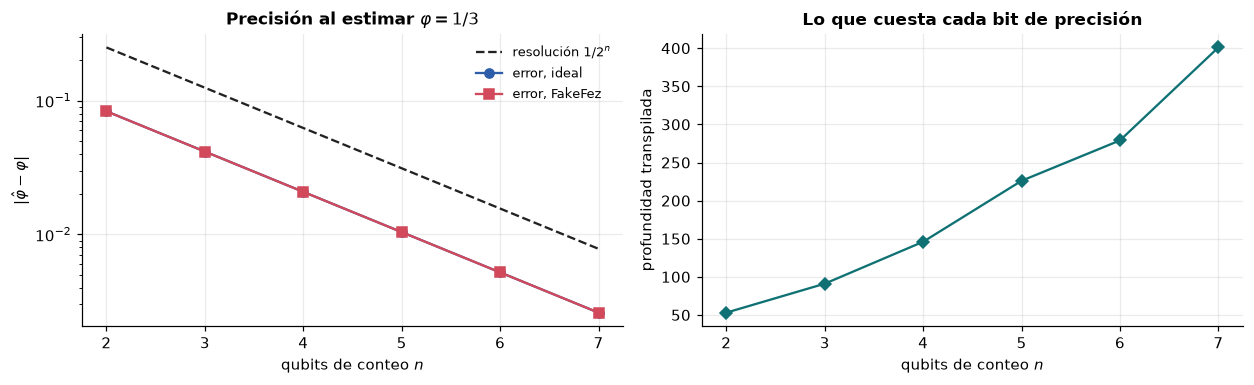

 n  error ideal  error ruido  profundidad
 2      0.08333      0.08333           53
 3      0.04167      0.04167           91
 4      0.02083      0.02083          146
 5      0.01042      0.01042          226
 6      0.00521      0.00521          279
 7      0.00260      0.00260          401


In [12]:
PHI_DIFICIL = 1 / 3
NS_CONTEO = [2, 3, 4, 5, 6, 7]
errores_ideal, errores_ruido, profundidades = [], [], []
for n in NS_CONTEO:
    ci = utils.correr_ideal(qpe(n, PHI_DIFICIL), shots=4096)
    cr = utils.correr_ruidoso(qpe(n, PHI_DIFICIL), backend_falso=fez, shots=4096)
    est_i = int(max(ci, key=ci.get), 2) / 2 ** n
    est_r = int(max(cr, key=cr.get), 2) / 2 ** n
    errores_ideal.append(abs(est_i - PHI_DIFICIL))
    errores_ruido.append(abs(est_r - PHI_DIFICIL))
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    profundidades.append(generate_preset_pass_manager(
        optimization_level=1, backend=fez).run(qpe(n, PHI_DIFICIL)).depth())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.6))
ax1.semilogy(NS_CONTEO, [1 / 2 ** n for n in NS_CONTEO], "--",
             color=utils.COLOR_TEORIA, label=r"resolución $1/2^n$")
ax1.semilogy(NS_CONTEO, np.maximum(errores_ideal, 1e-4), "o-",
             color=utils.COLOR_IDEAL, label="error, ideal")
ax1.semilogy(NS_CONTEO, np.maximum(errores_ruido, 1e-4), "s-",
             color=utils.COLOR_RUIDO, label="error, FakeFez")
ax1.set_xlabel("qubits de conteo $n$")
ax1.set_ylabel(r"$|\hat\varphi - \varphi|$")
ax1.set_title(r"Precisión al estimar $\varphi = 1/3$")
ax1.legend(fontsize=8.5)

ax2.plot(NS_CONTEO, profundidades, "D-", color=utils.COLOR_HARD)
ax2.set_xlabel("qubits de conteo $n$")
ax2.set_ylabel("profundidad transpilada")
ax2.set_title("Lo que cuesta cada bit de precisión")
utils.layout(fig)
plt.show()

print(f"{'n':>2} {'error ideal':>12} {'error ruido':>12} {'profundidad':>12}")
for n, ei, er, d in zip(NS_CONTEO, errores_ideal, errores_ruido, profundidades):
    print(f"{n:>2} {ei:>12.5f} {er:>12.5f} {d:>12}")

**Las dos curvas cuentan historias opuestas, y ahí está el dilema de NISQ.**
El error ideal baja como $1/2^n$: cada qubit de conteo agregado duplica la
precisión. Pero la profundidad crece, y a partir de cierto $n$ el ruido come
más de lo que la resolución gana: el error con ruido deja de bajar y empieza
a
subir.

**Ese cruce es el número de qubits de conteo óptimo para este chip.** No es
una elección de diseño: es una propiedad del hardware, y se mide.

---
# 7. QPE iterativa: un solo qubit de conteo

Hay una variante que evita el problema. En vez de $n$ qubits de conteo en
paralelo, se usa **uno solo, reutilizado $n$ veces**, empezando por el bit
menos significativo y realimentando el resultado como corrección de fase.

Es la QPE de Kitaev, y en NISQ funciona mucho mejor: la profundidad **no crece**
con los bits de precisión, y no hace falta IQFT.

$$\text{bit } j: \quad
H \;\to\; CU^{2^{n-1-j}} \;\to\; R_z(-\text{corrección}) \;\to\; H \;\to\;
\text{medir}$$

donde la corrección viene de los bits ya obtenidos. Lo implementamos con
retroalimentación clásica en Python —midiendo circuito por circuito— que es
lo que se hace en la práctica.

φ = 0.1250  →  bits 001  →  estimado 0.1250   (error 0.0000, 3 circuitos de profundidad fija)


φ = 0.3750  →  bits 011  →  estimado 0.3750   (error 0.0000, 3 circuitos de profundidad fija)


φ = 0.3333  →  bits 010101  →  estimado 0.3281   (error 0.0052, 6 circuitos de profundidad fija)


φ = 0.8125  →  bits 11010  →  estimado 0.8125   (error 0.0000, 5 circuitos de profundidad fija)

Ronda 0 (bit menos significativo) — todavía no hay nada que corregir:


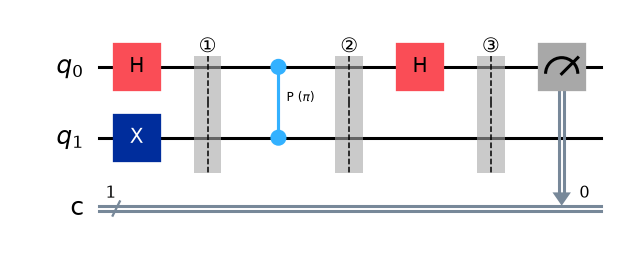

Ronda 1 — aparece la corrección de fase condicionada por el bit ya medido:


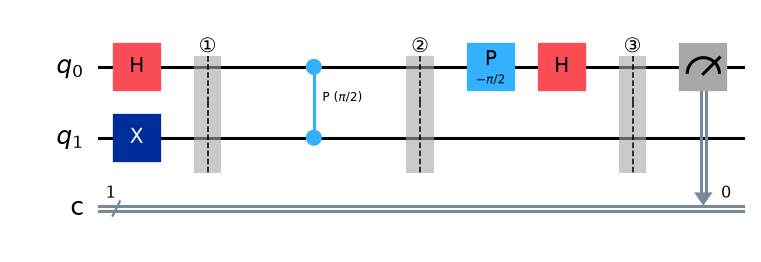

In [13]:
def ronda_iterativa(phi_frac: float, n_bits: int, j: int,
                    bits: str = "") -> QuantumCircuit:
    """Una ronda de la QPE de Kitaev: el circuito del bit j.

    `bits` son los ya medidos (de menos a más significativo), que entran como
    corrección de fase. Todas las rondas tienen la MISMA profundidad.
    """
    theta = 2 * np.pi * phi_frac
    qc = QuantumCircuit(2, 1)
    qc.x(1)                          # el autoestado de P(theta)
    qc.h(0)
    marca(qc, 1)
    qc.cp(theta * 2 ** (n_bits - 1 - j), 0, 1)     # U^(2^(n-1-j)) controlada
    marca(qc, 2)
    if bits:                         # descontar lo que ya sabemos
        correccion = -2 * np.pi * sum(int(b) / 2 ** (i + 2)
                                      for i, b in enumerate(bits))
        qc.p(correccion, 0)
    qc.h(0)
    marca(qc, 3)
    qc.measure(0, 0)
    return qc


def qpe_iterativa(phi_frac: float, n_bits: int, shots=1024,
                  backend_falso=None) -> str:
    """QPE de Kitaev: un qubit de conteo, n_bits circuitos, realimentando.

    Devuelve los bits de φ, del más significativo al menos.
    """
    bits = ""                       # se acumulan de menos a más significativo
    for j in range(n_bits):
        qc = ronda_iterativa(phi_frac, n_bits, j, bits)
        c = (utils.correr_ideal(qc, shots=shots) if backend_falso is None
             else utils.correr_ruidoso(qc, backend_falso=backend_falso, shots=shots))
        bits = max(c, key=c.get) + bits
    return bits


for phi, nb in [(0.125, 3), (0.375, 3), (1 / 3, 6), (0.8125, 5)]:
    b = qpe_iterativa(phi, nb)
    est = int(b, 2) / 2 ** nb
    print(f"φ = {phi:.4f}  →  bits {b}  →  estimado {est:.4f}   "
          f"(error {abs(est - phi):.4f}, {nb} circuitos de profundidad fija)")

print("\nRonda 0 (bit menos significativo) — todavía no hay nada que corregir:")
display(ronda_iterativa(0.125, 3, 0).draw("mpl", style="iqp"))
print("Ronda 1 — aparece la corrección de fase condicionada por el bit ya medido:")
display(ronda_iterativa(0.125, 3, 1, bits="1").draw("mpl", style="iqp"))

### La cuenta, etapa por etapa ($\varphi = 1/8$, tres bits)

Las tres barreras se repiten **idénticas en cada ronda**; lo único que
cambia
entre rondas es la potencia de $U$ y la corrección.

#### Ronda 0 — el bit menos significativo

**①** Dado que se aplica $X$ al target (que queda en el autoestado
$|1\rangle$) y $H$ al contador:
$$|\psi_1\rangle = |+\rangle_c \otimes |1\rangle_t .$$

**②** Dado que se aplica $U^{4}$ controlada — con $n=3$ y $j=0$, el
exponente
es $2^{n-1-j} = 4$. Por retroceso de fase el contador queda en
$$\frac{|0\rangle + e^{2\pi i\,(4\varphi)}|1\rangle}{\sqrt2}
 = \frac{|0\rangle + e^{i\pi}|1\rangle}{\sqrt2} = |-\rangle ,$$
porque $4\varphi = 4/8 = 1/2$.

**Por qué se empieza por la potencia más alta:** multiplicar $\varphi$ por
$2^{n-1}$ convierte a todos los bits **menos el último** en múltiplos
enteros
de $2\pi$, o sea invisibles. Lo que sobrevive es exactamente el bit menos
significativo, y por eso sale limpio y determinista.

**③** Dado que se aplica $H$, que manda $|-\rangle \to |1\rangle$: la
medición da **$c_0 = 1$** con probabilidad 1. Es el último dígito de
$0.001_2$.

#### Ronda 1 — y acá entra la realimentación

**②** Ahora la potencia es $2^{3-1-1} = 2$, así que la fase acumulada es
$2\pi(2\varphi) = \pi/2$. Pero esa fase **está contaminada** por el bit que
ya medimos: parte de ella viene de $c_0$, no del bit que buscamos.

La corrección lo descuenta: con $c_0 = 1$ se aplica $P(-2\pi/4) =
P(-\pi/2)$.
Neto: fase cero, el contador vuelve a $|+\rangle$.

**③** $H$ lo manda a $|0\rangle$ y sale **$c_1 = 0$**. Ronda 2, igual, con
$U^{1}$ y las correcciones de $c_0$ y $c_1$: sale **$c_2 = 0$**.

### Cómo llega al final

Los bits salen **de menos a más significativo**, y se van acumulando a la
izquierda: `1` → `01` → `001`, que leído como fracción binaria es
$0.001_2 = 1/8 = \varphi$.

Y el costo: **cada ronda tiene una sola $CU$ y dos $H$**, así que la
profundidad es constante y no crece con la precisión. Lo que crece es la
cantidad de rondas, y la latencia de tener que esperar cada resultado antes
de
armar la siguiente. En `10_circuitos_dinamicos.ipynb` esa espera se elimina
metiendo las rondas en un solo circuito con `reset` y feed-forward.

La QPE iterativa da los mismos bits con **circuitos de profundidad
constante**
—cada uno tiene una sola $CU$, dos $H$ y una medición— a cambio de correr
$n$
circuitos en vez de uno y de tener que esperar el resultado de cada uno
antes
de armar el siguiente.

En hardware NISQ ese intercambio casi siempre conviene: la profundidad es el
recurso escaso, no la cantidad de circuitos. La contra es la latencia,
porque
hay que ida y vuelta con la máquina entre bit y bit.

---
# 8. Hardware real

QPE con 3 qubits de conteo sobre una fase conocida es la demostración
honesta
que reemplaza a Shor en hardware. Entra cómoda en NISQ y el resultado es
inequívoco: un pico donde tiene que estar.

In [14]:
if service is not None:
    print(f"{'backend':<16} {'qubits':>6} {'cola':>6}  {'estado':<10}")
    print("-" * 46)
    for b in service.backends(simulator=False):
        st = b.status()
        print(f"{b.name:<16} {b.num_qubits:>6} {st.pending_jobs:>6}  {st.status_msg:<10}")
else:
    print("sin autenticar")

sin autenticar


In [15]:
BACKEND_FIJO = None

backend = None
if service is not None:
    backend = (service.backend(BACKEND_FIJO) if BACKEND_FIJO
               else service.least_busy(operational=True, simulator=False))
    st = backend.status()
    print(f"elegido: {backend.name}  ·  {st.status_msg}  ·  cola {st.pending_jobs}")
else:
    print("sin autenticar: no hay backend")

sin autenticar: no hay backend


In [16]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

SHOTS_HW = 4096
t_qpe = None
CASOS_HW = [("phi_1_8", qpe(3, 0.125)),
            ("phi_3_8", qpe(3, 0.375)),
            ("control_target_0", qpe(3, 0.125, prep_target=lambda q, t: None)),
            ("phi_1_3", qpe(3, 1 / 3)),
            ("superpos_75", qpe_superposicion(3, 0.125, np.pi / 3)),
            ("n4_phi_1_3", qpe(4, 1 / 3)),
            ("n5_phi_1_3", qpe(5, 1 / 3))]

if backend is not None:
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
    t_qpe = pm.run([c for _, c in CASOS_HW])
    print("=== QPE: 7 circuitos en un job ===")
    costo = utils.informe_transpilacion(t_qpe, shots=SHOTS_HW,
                                        nombre_backend=backend.name)
else:
    print("sin backend: nada que transpilar")

sin backend: nada que transpilar


### El envío

Siete circuitos en un solo job: los dos casos exactos, el control con el
target en $|0\rangle$, el caso no representable, la superposición de
autoestados, y dos con más qubits de conteo para ver dónde empieza a ganar
el
ruido.

In [17]:
ENVIAR_QPE = False    # ponerlo en True para gastar QPU

if ENVIAR_QPE:
    from qiskit_ibm_runtime import SamplerV2

    job = SamplerV2(mode=backend).run(t_qpe, shots=SHOTS_HW)
    utils.registrar_job(job, backend.name,
                        f"08 QPE: 7 casos, {SHOTS_HW} shots",
                        notebook="08", experimento="qpe",
                        n_circuitos=len(t_qpe), shots=SHOTS_HW,
                        orden=[n for n, _ in CASOS_HW])
else:
    print("modo simulación — no se envió nada")

modo simulación — no se envió nada


In [18]:
registros = utils.listar_jobs(filtro="08 ")

In [19]:
JOB_ID = ""   # vacío = el último job de QPE

if not JOB_ID:
    reg = utils.ultimo_job(experimento="qpe")
    JOB_ID = reg["job_id"] if reg else ""
    if reg:
        print(f"último: {JOB_ID}  ({reg['backend']}, {reg['fecha']})")

if JOB_ID and service is not None:
    res = utils.recuperar(service, JOB_ID).result()
    hw = [utils.counts_de_resultado(res, i) for i in range(len(res))]

    fig, ejes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
    for ax, (nombre, _), ci, ch in zip(ejes, CASOS_HW[:4], counts_qpe, hw[:4]):
        utils.comparar_conteos({"ideal": ci, "hardware": ch},
                               claves=utils.claves_completas(3), ax=ax,
                               titulo=nombre)
        ax.set_xlabel("conteo")
    utils.layout(fig)
    plt.show()

    for (nombre, _), c in zip(CASOS_HW, hw):
        n_bits = len(next(iter(c)))
        mejor = max(c, key=c.get)
        print(f"{nombre:<18} pico {mejor} = {int(mejor, 2) / 2 ** n_bits:.4f}   "
              f"(prob {c[mejor] / sum(c.values()):.3f})")
else:
    print("sin JOB_ID o sin autenticar: nada que recuperar")

sin JOB_ID o sin autenticar: nada que recuperar


---
## Qué quedó establecido

1. **El retroceso de fase** convierte una fase global —invisible— en una
fase
   relativa del qubit de control, que sí se mide. El target no se altera.
2. **Con $n$ qubits de conteo y la IQFT**, la fase sale escrita en binario,
de
   una sola vez, con precisión $1/2^n$. Si $\varphi$ cabe en $n$ bits, es
   exacta y determinista.
3. **El control con el target en $|0\rangle$** prueba que el registro lee el
   autovalor del estado que le diste, no una propiedad del circuito.
4. **No hace falta el autoestado.** Con una superposición, QPE muestrea el
   espectro con probabilidad $|c_k|^2$ **y deja el target proyectado sobre
     el
   autoestado correspondiente**. El requisito real es tener solapamiento.
5. Eso es lo que hace viable la química cuántica (Hartree-Fock como semilla)
y
   lo que hace funcionar a Shor (donde $|1\rangle$ es la superposición
   uniforme de todos los autoestados).
6. **Más qubits de conteo dan más precisión y más ruido.** El óptimo en un
   chip real es un cruce de dos curvas, y se mide. La QPE **iterativa**
     evita
   el dilema: profundidad constante, más circuitos.

**Siguiente:** `09_shor_simulador.ipynb` — el truco del $|1\rangle$ puesto a
trabajar, y por qué en hardware NISQ sale ruido plano.